# DIP Lab 02 – Gamma Correction & Histogram Equalization (HE / AHE / CLAHE)
1. **Gamma correction:** từ `parrot.jpg`, tạo ảnh giống `Contrast_gamma.png` nhất + PSNR.
2. **Histogram** trên `brain.jpg`: (a) hiển thị histogram · (b) HE · (c) AHE ≥ 2 tùy chọn · (d) CLAHE ≥ 2 `clipLimit`.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


def save_show(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


def show_gray(ax, img, title):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

## 1. Gamma correction
- `s = 255·(r/255)^γ`, cài bằng **bảng tra (LUT)** 256 phần tử, có **làm tròn**.
- Tìm γ cho **PSNR lớn nhất** so với ảnh tham chiếu: quét thô (bước 0.1) rồi quét mịn (bước 0.01).

Quét thô : γ = 1.5
Quét mịn : γ = 1.50 → MSE = 0.00, PSNR = inf dB


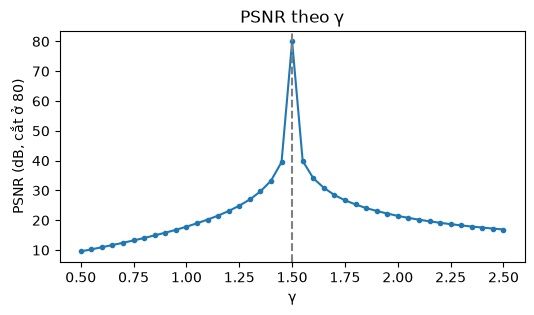

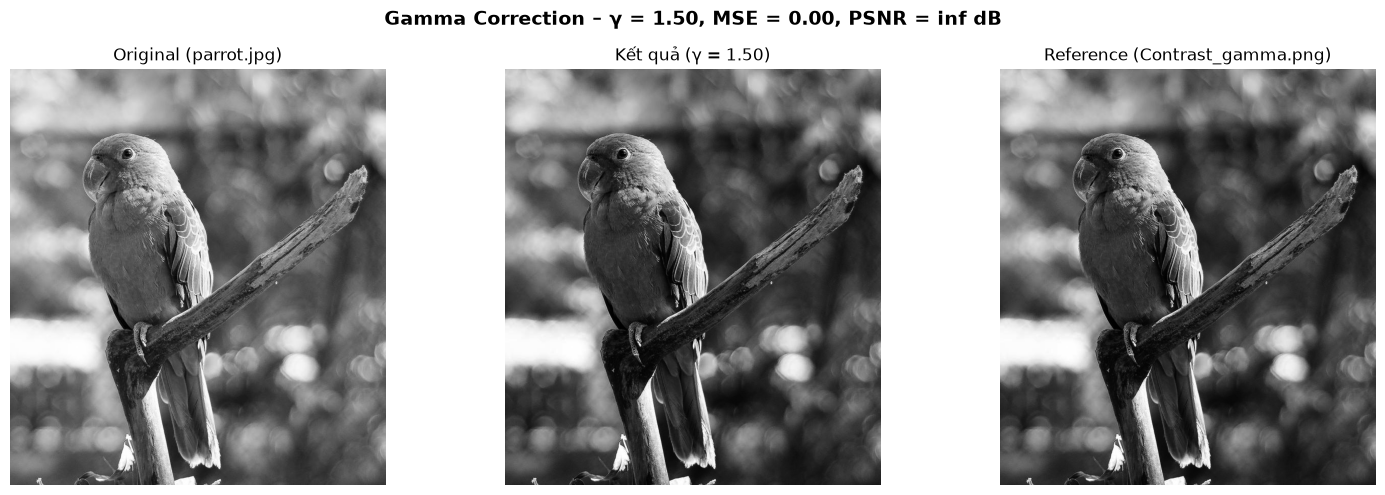

In [2]:
def apply_gamma(img, gamma):
    lut = np.round(255.0 * (np.arange(256) / 255.0) ** gamma).astype(np.uint8)
    return cv2.LUT(img, lut)


def mse_psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return mse, (float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse))


parrot = cv2.imread(str(DATA_DIR / "parrot.jpg"))
reference = cv2.imread(str(DATA_DIR / "Contrast_gamma.png"))


def search(gammas):
    return max(((g, *mse_psnr(apply_gamma(parrot, g), reference)) for g in gammas), key=lambda t: t[2])


coarse_gamma, _, coarse_psnr = search(np.round(np.arange(0.1, 2.51, 0.1), 2))
best_gamma, best_mse, best_psnr = search(np.round(np.arange(coarse_gamma - 0.1, coarse_gamma + 0.101, 0.01), 2))
print(f"Quét thô : γ = {coarse_gamma:.1f}")
print(f"Quét mịn : γ = {best_gamma:.2f} → MSE = {best_mse:.2f}, PSNR = {best_psnr:.2f} dB")

gammas = np.round(np.arange(0.5, 2.51, 0.05), 2)
plt.figure(figsize=(6, 3))
plt.plot(gammas, [min(mse_psnr(apply_gamma(parrot, g), reference)[1], 80) for g in gammas], "o-", ms=3)
plt.axvline(best_gamma, ls="--", color="gray")
plt.xlabel("γ"); plt.ylabel("PSNR (dB, cắt ở 80)"); plt.title("PSNR theo γ")
plt.show()

best_image = apply_gamma(parrot, best_gamma)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, (parrot, best_image, reference),
                          ("Original (parrot.jpg)", f"Kết quả (γ = {best_gamma:.2f})", "Reference (Contrast_gamma.png)")):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
fig.suptitle(f"Gamma Correction – γ = {best_gamma:.2f}, MSE = {best_mse:.2f}, PSNR = {best_psnr:.2f} dB",
             fontsize=14, fontweight="bold")
save_show("Q1_gamma_correction.png")

## 2a. Histogram của `brain.jpg`

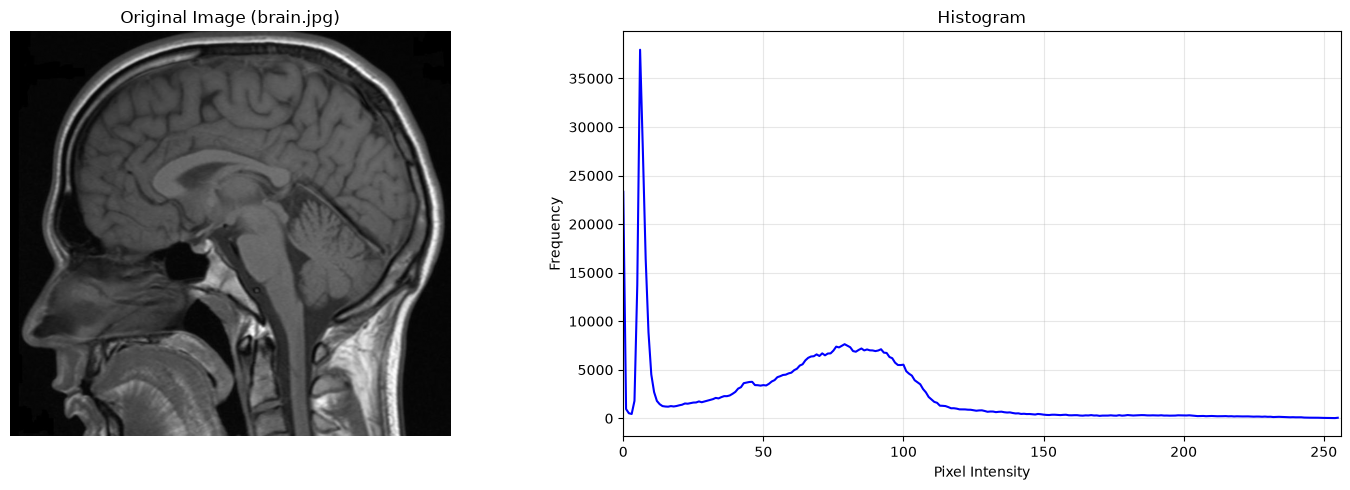

In [3]:
brain = cv2.imread(str(DATA_DIR / "brain.jpg"), cv2.IMREAD_GRAYSCALE)
hist = cv2.calcHist([brain], [0], None, [256], [0, 256])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
show_gray(axes[0], brain, "Original Image (brain.jpg)")
axes[1].plot(hist, color="blue")
axes[1].set(title="Histogram", xlabel="Pixel Intensity", ylabel="Frequency", xlim=[0, 256])
axes[1].grid(alpha=0.3)
save_show("Q2a_histogram.png")

## 2b. Histogram Equalization (toàn cục)
Dùng CDF của histogram để kéo giãn mức xám ra toàn dải 0–255.

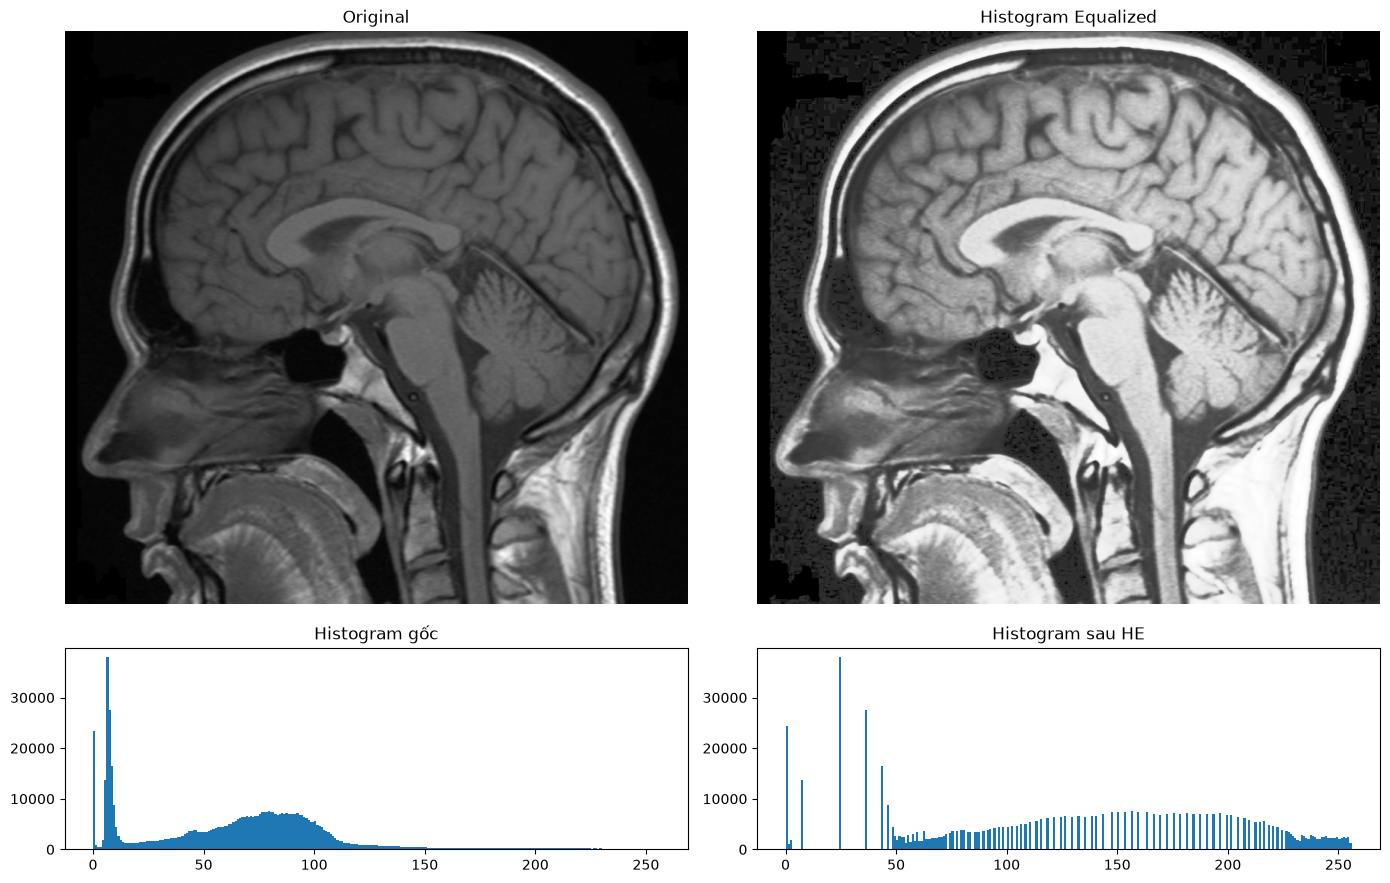

In [4]:
equalized = cv2.equalizeHist(brain)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"height_ratios": [3, 1]})
show_gray(axes[0, 0], brain, "Original")
show_gray(axes[0, 1], equalized, "Histogram Equalized")
axes[1, 0].hist(brain.ravel(), bins=256, range=(0, 256)); axes[1, 0].set_title("Histogram gốc")
axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256)); axes[1, 1].set_title("Histogram sau HE")
save_show("Q2b_hist_equalization.png")

## 2c. Adaptive HE (AHE) – thay đổi kích thước cửa sổ
OpenCV không có hàm AHE riêng → dùng **CLAHE với `clipLimit` rất lớn (40)**: gần như không cắt histogram, tương đương AHE.

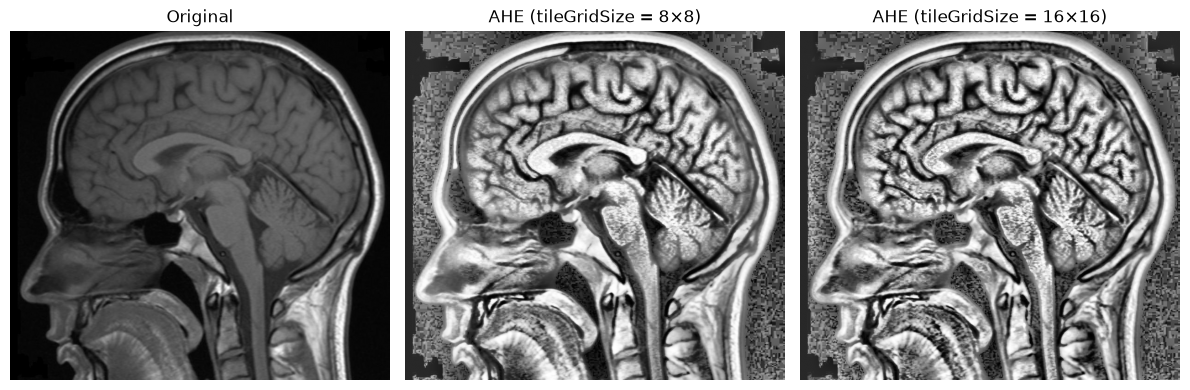

In [5]:
ahe = {size: cv2.createCLAHE(clipLimit=40.0, tileGridSize=(size, size)).apply(brain) for size in (8, 16)}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
show_gray(axes[0], brain, "Original")
for ax, (size, img) in zip(axes[1:], ahe.items()):
    show_gray(ax, img, f"AHE (tileGridSize = {size}×{size})")
save_show("Q2c_adaptive_hist_eq.png")

## 2d. CLAHE – thay đổi `clipLimit` (tile 8×8)

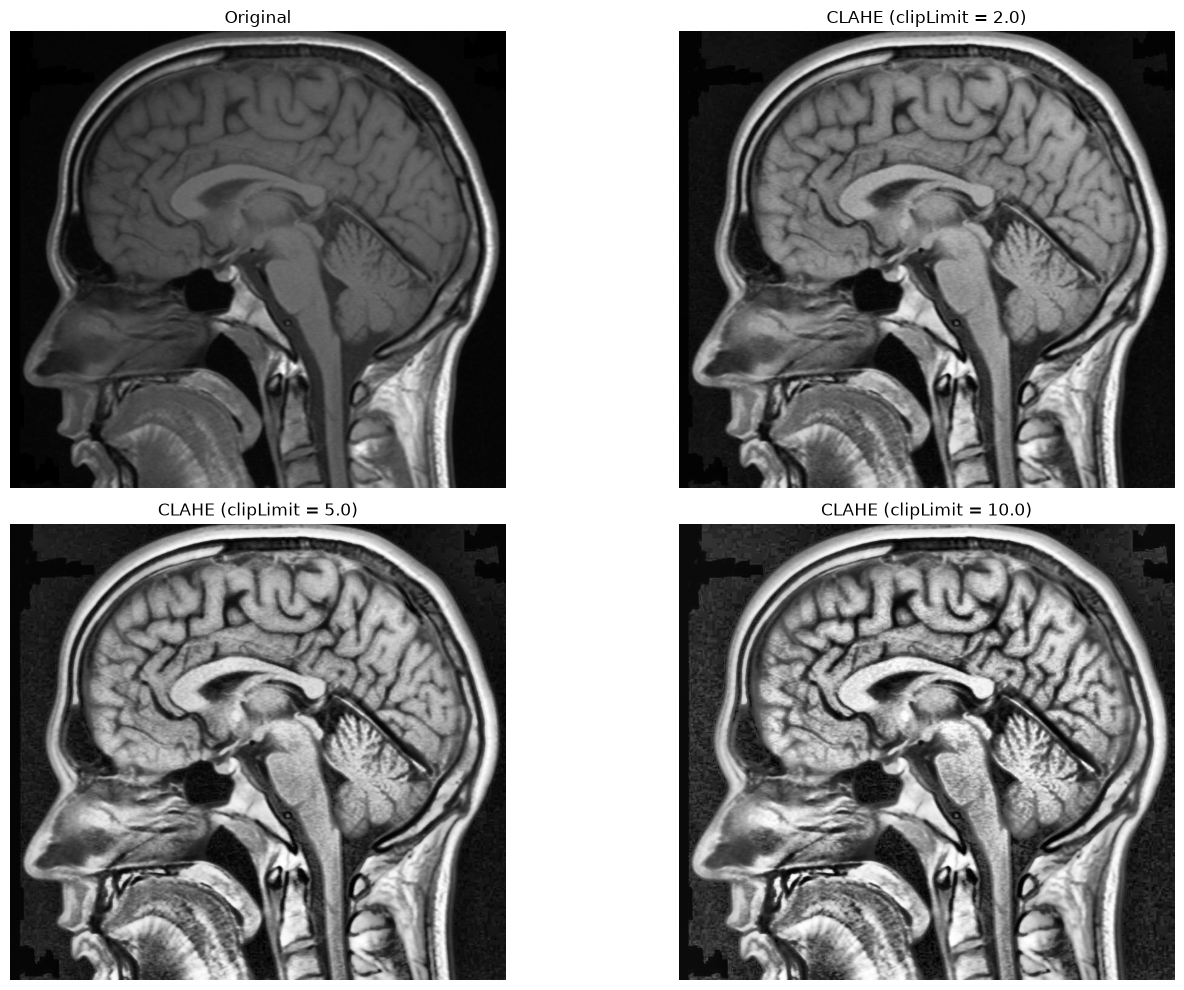

In [6]:
clahe = {c: cv2.createCLAHE(clipLimit=c, tileGridSize=(8, 8)).apply(brain) for c in (2.0, 5.0, 10.0)}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
show_gray(axes[0, 0], brain, "Original")
for ax, (c, img) in zip(axes.ravel()[1:], clahe.items()):
    show_gray(ax, img, f"CLAHE (clipLimit = {c})")
save_show("Q2d_clahe.png")

**Nhận xét:**
- AHE: nếp cuộn não rất rõ nhưng **nền đen biến thành nhiễu dạng khối** – ô gần đồng nhất cũng bị kéo giãn hết dải xám. Lưới 16×16 chi tiết cục bộ mạnh hơn và nhiễu hơn 8×8.
- CLAHE: `clipLimit` = 2 tự nhiên nhất, nền vẫn đen; tăng lên 5 → 10 thì tương phản tăng, nhiễu nền xuất hiện dần (tiến về AHE).

---
## Luyện tập thêm (không thuộc yêu cầu lab)
### A. Không gian màu + biến đổi điểm (log, gamma) trên `leaf.jpg`

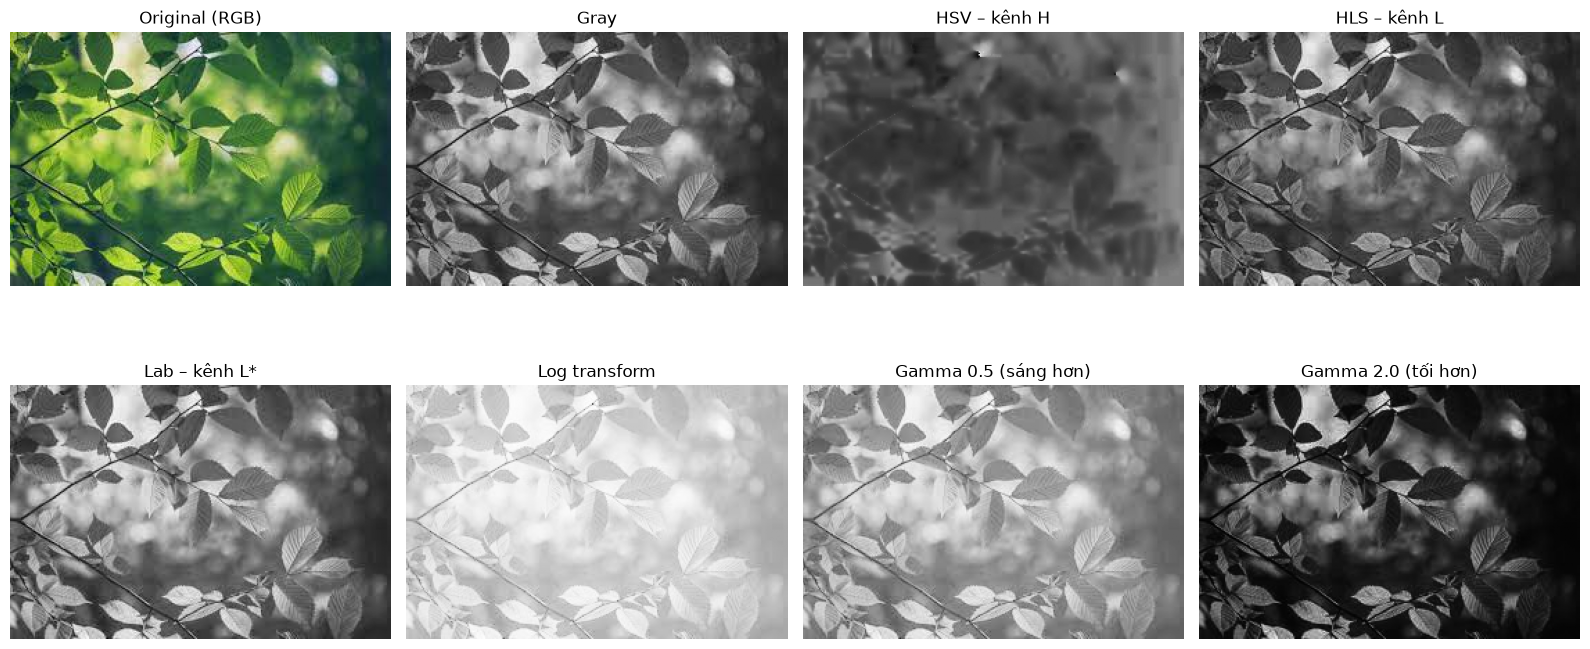

In [7]:
leaf = cv2.imread(str(DATA_DIR / "leaf.jpg"))
leaf_rgb = cv2.cvtColor(leaf, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(leaf, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(leaf, cv2.COLOR_BGR2HSV)
hls = cv2.cvtColor(leaf, cv2.COLOR_BGR2HLS)
lab = cv2.cvtColor(leaf, cv2.COLOR_BGR2Lab)

c = 255 / np.log(1 + gray.max())
log_img = np.round(c * np.log1p(gray.astype(np.float32))).astype(np.uint8)
gamma_low, gamma_high = apply_gamma(gray, 0.5), apply_gamma(gray, 2.0)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
axes[0].imshow(leaf_rgb); axes[0].set_title("Original (RGB)"); axes[0].axis("off")
for ax, img, title in [(axes[1], gray, "Gray"), (axes[5], log_img, "Log transform"),
                       (axes[6], gamma_low, "Gamma 0.5 (sáng hơn)"), (axes[7], gamma_high, "Gamma 2.0 (tối hơn)")]:
    show_gray(ax, img, title)
for ax, img, title in [(axes[2], hsv[:, :, 0], "HSV – kênh H"), (axes[3], hls[:, :, 1], "HLS – kênh L"),
                       (axes[4], lab[:, :, 0], "Lab – kênh L*")]:
    ax.imshow(img, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

### B. Histogram matching + nội suy khi phóng to (`leaf.jpg` theo histogram của `flower.jpg`)

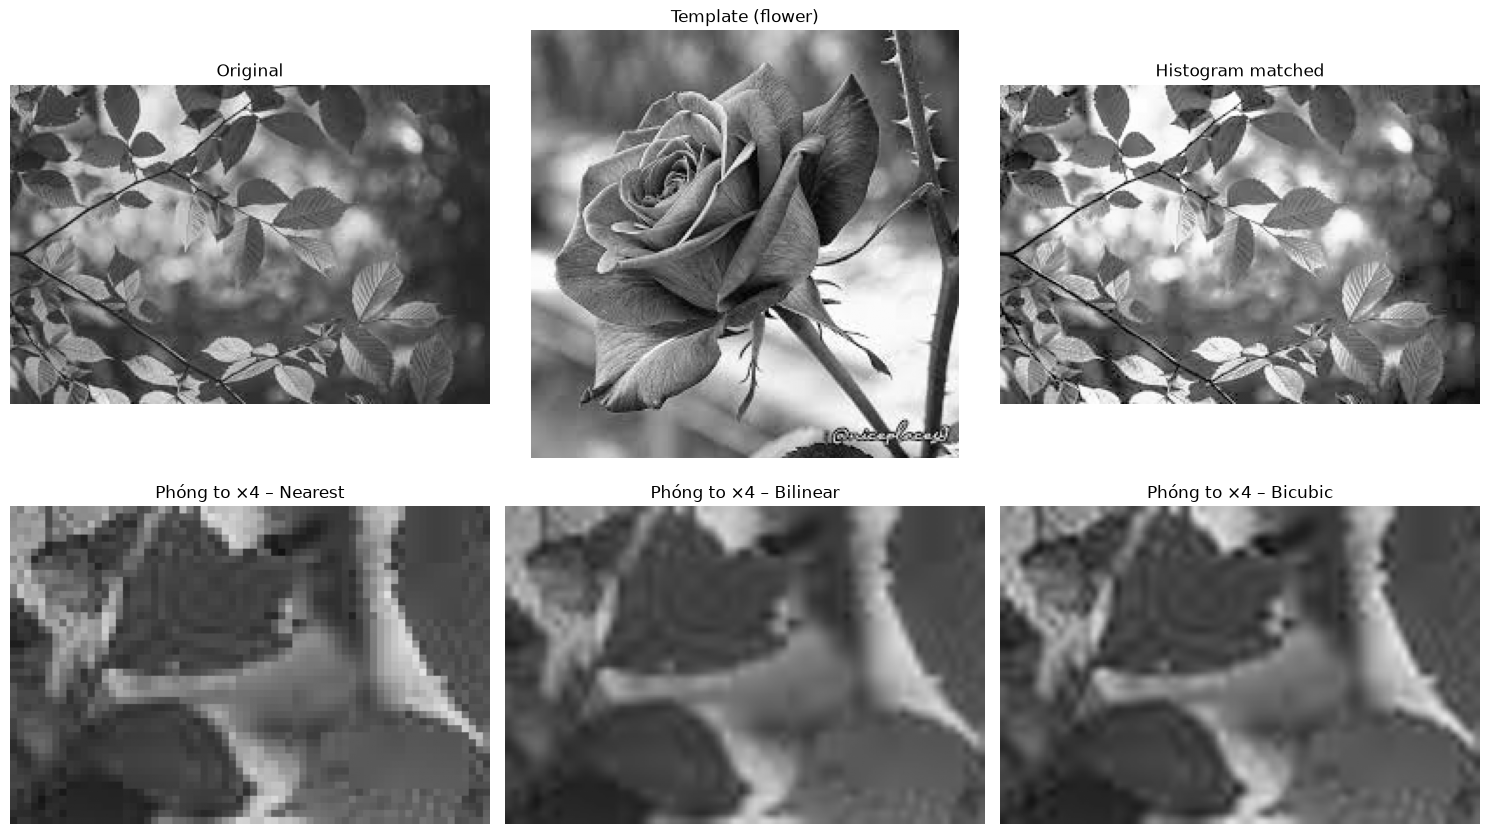

In [8]:
def hist_match(source, template):
    """Ánh xạ mức xám sao cho CDF của source khớp CDF của template."""
    s_values, bin_idx, s_counts = np.unique(source.ravel(), return_inverse=True, return_counts=True)
    t_values, t_counts = np.unique(template.ravel(), return_counts=True)
    s_cdf = np.cumsum(s_counts) / source.size
    t_cdf = np.cumsum(t_counts) / template.size
    return np.interp(s_cdf, t_cdf, t_values)[bin_idx].reshape(source.shape).astype(np.uint8)


flower = cv2.imread(str(DATA_DIR / "flower.jpg"), cv2.IMREAD_GRAYSCALE)
matched = hist_match(gray, flower)
crop = gray[: gray.shape[0] // 4, : gray.shape[1] // 4]
resized = {name: cv2.resize(crop, None, fx=4, fy=4, interpolation=m)
           for name, m in [("Nearest", cv2.INTER_NEAREST), ("Bilinear", cv2.INTER_LINEAR), ("Bicubic", cv2.INTER_CUBIC)]}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
show_gray(axes[0, 0], gray, "Original")
show_gray(axes[0, 1], flower, "Template (flower)")
show_gray(axes[0, 2], matched, "Histogram matched")
for ax, (name, img) in zip(axes[1], resized.items()):
    show_gray(ax, img, f"Phóng to ×4 – {name}")
plt.tight_layout()
plt.show()